# Predict with all EpiHydra clocks at once

Builds one `MultiClockPredictor`: the frozen, LoRA-merged backbone from `best_model.pt` with one head per clock.

- `"age"` (always included) uses the head stored in `best_model.pt`.
- Every other clock uses `best_head_<clock>.pt` from `HEAD_PATH`.

Each batch goes through the backbone **once** and the hidden states fan out to every head. The output is a table of predictions (plus true labels where available) with one row per sample. Metrics come later.

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path

# ── Which clocks to predict ──────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH.
# Or give a list, e.g. ["age", "horvath_age", "phenoage_age"]; "age" is always added first.
CLOCKS     = None

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/combined_test/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks3_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261115_120827"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"           # LoRA backbone + the "age" head

# ── Model settings (must match training) ─────────────────────────
NUM_HEADS  = 4 # N clocks exlcuding "age" (chron age)


SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 32
RANDOM_STATE = 42

# Where to save the prediction table (None = don't save)
OUT_CSV = None

## Imports

In [2]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
from epihydra import VocabWrapper, build_multiclock_dataloaders, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device: {device}")
print(f"Evaluating clocks: '{clock_names}'")

Using device: cuda
Evaluating clocks: '['age', 'hannum_age', 'horvath_age', 'phenoage_age']'


## Load data, config and vocab

In [3]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

# MethylGPT pre-training config (layer sizes, number of CpGs, ...)
with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

# CpG vocabulary used for tokenisation
vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
One dataset carries every clock's label. Samples are kept if they have a label for at least one clock, so missing labels show up as NaN in the `_true` columns.

The saved training scalers from `HEAD_PATH/scalers.pkl` are passed in and reused. Any clock without a saved scaler (i.e. `"age"`) gets one fitted on this training split.

In [4]:
scalers = eu.load_scalers(HEAD_PATH, EPIHYDRA_PATH)

dataloader = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = scalers,   # reused where available, fitted otherwise
    mask_ratio   = 0,
    **SPLIT_RATIOS,
)

scalers = dataloader["scalers"]         # the scalers actually used, one per clock

Samples in meta : 1239
Samples in CpG  : 1239
Common samples  : 1239
Samples after drop : 1239
  age                 : 1239 labeled
  hannum_age          : 1239 labeled
  horvath_age         : 1239 labeled
  phenoage_age        : 1239 labeled

Vocab CpGs : 49,159 | Present : 45,069 (91.7%) | Missing : 4,090
ℹ  age                 : reusing supplied pre-fitted scaler.
ℹ  hannum_age          : reusing supplied pre-fitted scaler.
ℹ  horvath_age         : reusing supplied pre-fitted scaler.
ℹ  phenoage_age        : reusing supplied pre-fitted scaler.
✓ Single multi-clock loader built (1239 samples, no masking).



/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


## Build the multi-clock model
Rebuilds the backbone the heads were trained on (LoRA adapters loaded from `best_model.pt`, merged and frozen), then loads one head per clock.

In [5]:
mc_model  = eu.build_multiclock_model(MODEL_PATH, vocab, pretrain_config, device,
                                      ckpt=EPIHYDRA_PATH, head_path=HEAD_PATH,
                                      clock_names=clock_names)

I0000 00:00:1794809233.384997 3362262 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794809238.502519 3362262 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794809258.896981 3362262 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


LoRA from checkpoint: r=16, alpha=32


/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739/best_model.pt
  source run   : nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739
  source epoch : 28  (valid MAE 3.119)
  lora_r=16 lora_alpha=32 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head hannum_age           <- best_head_hannum_age.pt (epoch 61)
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 47)
  loaded head phenoage_age         <- best_head_phenoage_age.pt (epoch 47)


## Predict
One forward pass through the backbone per batch, shared across all heads. Loaders are rebuilt unshuffled so each row lines up with its sample ID.

In [6]:
loader = eu.ordered_loader(dataloader['loader'])
predictions  = eu.predict_multiclock(mc_model, loader, scalers, device, clock_names)

print(f"{len(predictions)} samples x {len(clock_names)} clocks")

1239 samples x 4 clocks


## Prediction table

In [7]:
pred_cols = [f"{c}_pred" for c in clock_names]

# Predictions only (one column per clock)
display(predictions[pred_cols].astype(float).round(2))

,age_pred,hannum_age_pred,horvath_age_pred,phenoage_age_pred
ID,,,,
GSM2250273,45.53,58.51,53.36,47.79
GSM2250274,57.28,70.38,63.45,59.84
GSM2250275,33.20,48.81,40.08,36.70
GSM2250276,45.57,55.31,50.42,43.79
GSM2250277,43.29,55.25,49.87,42.76
...,...,...,...,...
GSM5414847,73.14,80.81,74.23,67.61
GSM5414848,43.75,57.09,49.97,46.14
GSM5414849,64.41,70.83,67.75,62.55


In [8]:
# Full table: predicted and true values side by side, per clock
display(predictions)

if OUT_CSV is not None:
    predictions.to_csv(OUT_CSV)
    print(f"Saved to {OUT_CSV}")

,age_pred,age_true,hannum_age_pred,hannum_age_true,horvath_age_pred,horvath_age_true,phenoage_age_pred,phenoage_age_true
ID,,,,,,,,
GSM2250273,45.530472,47.299999,58.507877,56.687447,53.363651,57.724472,47.789585,60.573990
GSM2250274,57.275295,60.400002,70.382179,70.836975,63.447544,62.917908,59.844765,64.903435
GSM2250275,33.199413,30.100000,48.808678,46.062206,40.081905,38.569855,36.704700,31.926306
GSM2250276,45.570904,47.700001,55.311802,53.376507,50.421627,55.671482,43.790794,51.839695
GSM2250277,43.286625,46.900002,55.245216,48.774784,49.867332,50.631992,42.761692,43.119724
...,...,...,...,...,...,...,...,...
GSM5414847,73.143951,77.000000,80.813812,87.572296,74.234962,75.296867,67.607124,74.434883
GSM5414848,43.751568,40.000000,57.087399,52.701679,49.973927,52.728252,46.143024,43.503994
GSM5414849,64.411140,61.000000,70.826080,67.437790,67.753983,65.492096,62.549828,64.890053


In [9]:
cross = eu.pairwise_metrics(predictions, clock_names)

for metric in eu.METRICS:
    display(eu.style_metric_table(cross[metric], metric))

True clock,age,hannum_age,horvath_age,phenoage_age
Pred clock,,,,
age,4.662,8.846,6.484,4.749
hannum_age,9.467,3.153,5.757,11.077
horvath_age,5.576,3.974,3.092,6.701
phenoage_age,5.149,9.001,6.445,3.955


True clock,age,hannum_age,horvath_age,phenoage_age
Pred clock,,,,
age,0.939,0.964,0.944,0.937
hannum_age,0.936,0.978,0.959,0.954
horvath_age,0.938,0.971,0.963,0.948
phenoage_age,0.931,0.968,0.953,0.958


True clock,age,hannum_age,horvath_age,phenoage_age
Pred clock,,,,
age,0.867,0.594,0.730,0.878
hannum_age,0.649,0.935,0.802,0.539
horvath_age,0.840,0.899,0.920,0.799
phenoage_age,0.848,0.596,0.753,0.917


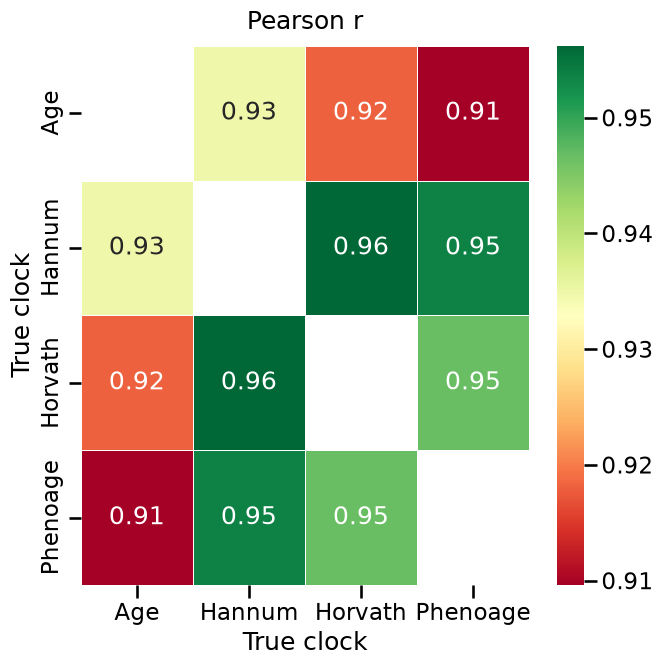

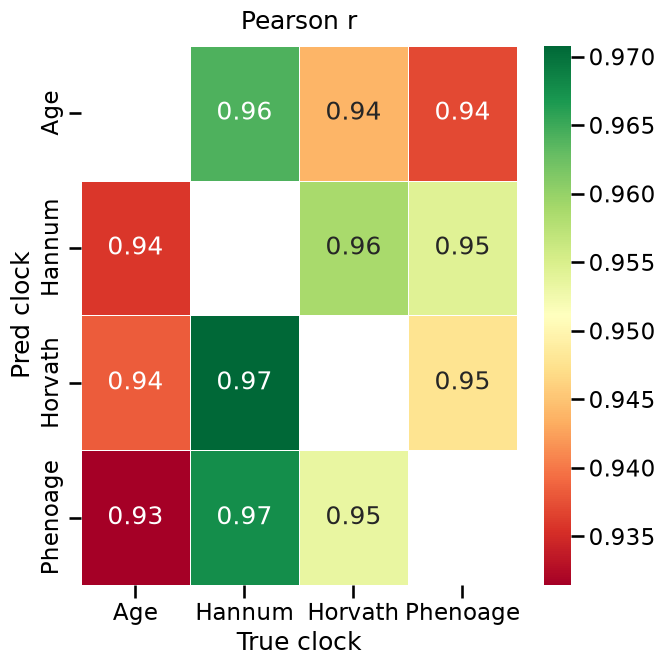

In [10]:
m = 'pearson_r'
fig_true  = eu.plot_metric_heatmap(eu.pairwise_metrics(predictions, clock_names, rows="true")[m], m)
fig_cross = eu.plot_metric_heatmap(cross[m] , m)

In [11]:
import numpy as np

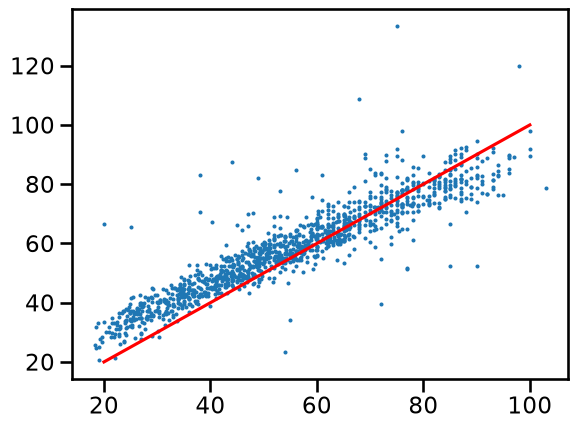

In [14]:
plt.scatter(predictions['age_true'], predictions['horvath_age_true'] , s = 2)
plt.plot(np.linspace(20,100 , 100) , np.linspace(20,100,100) , c = 'r')

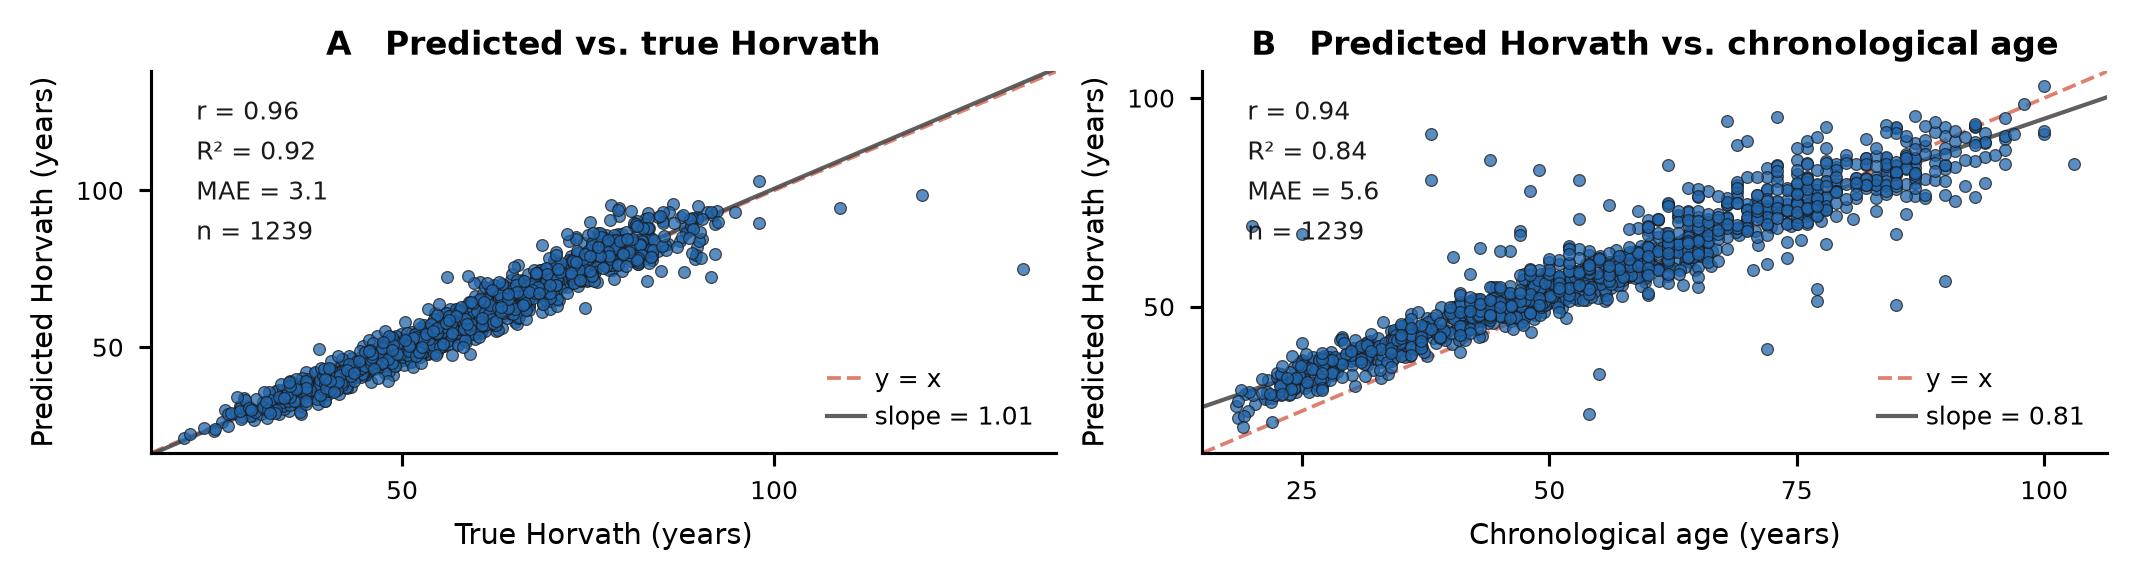

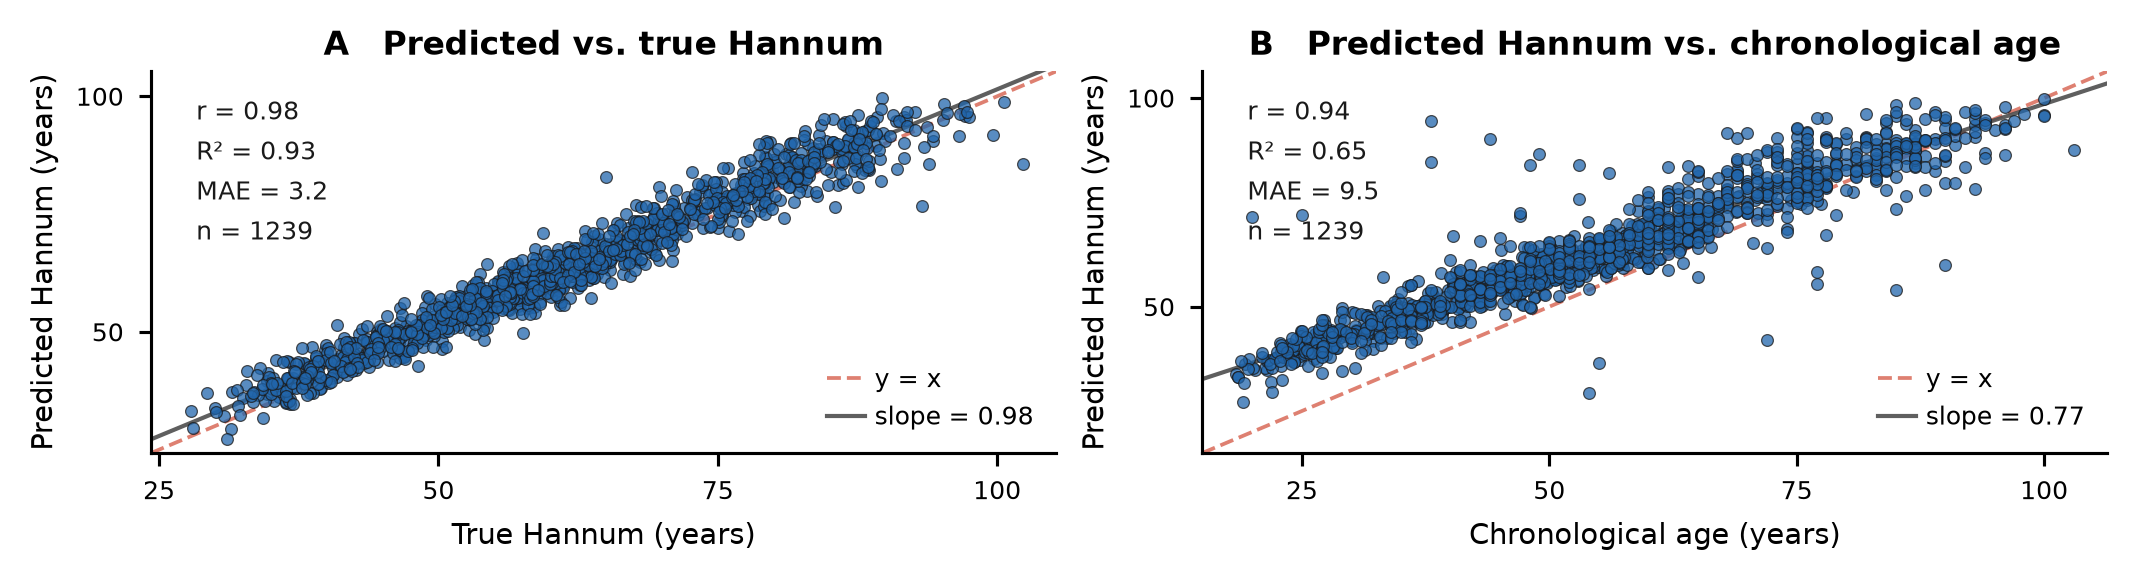

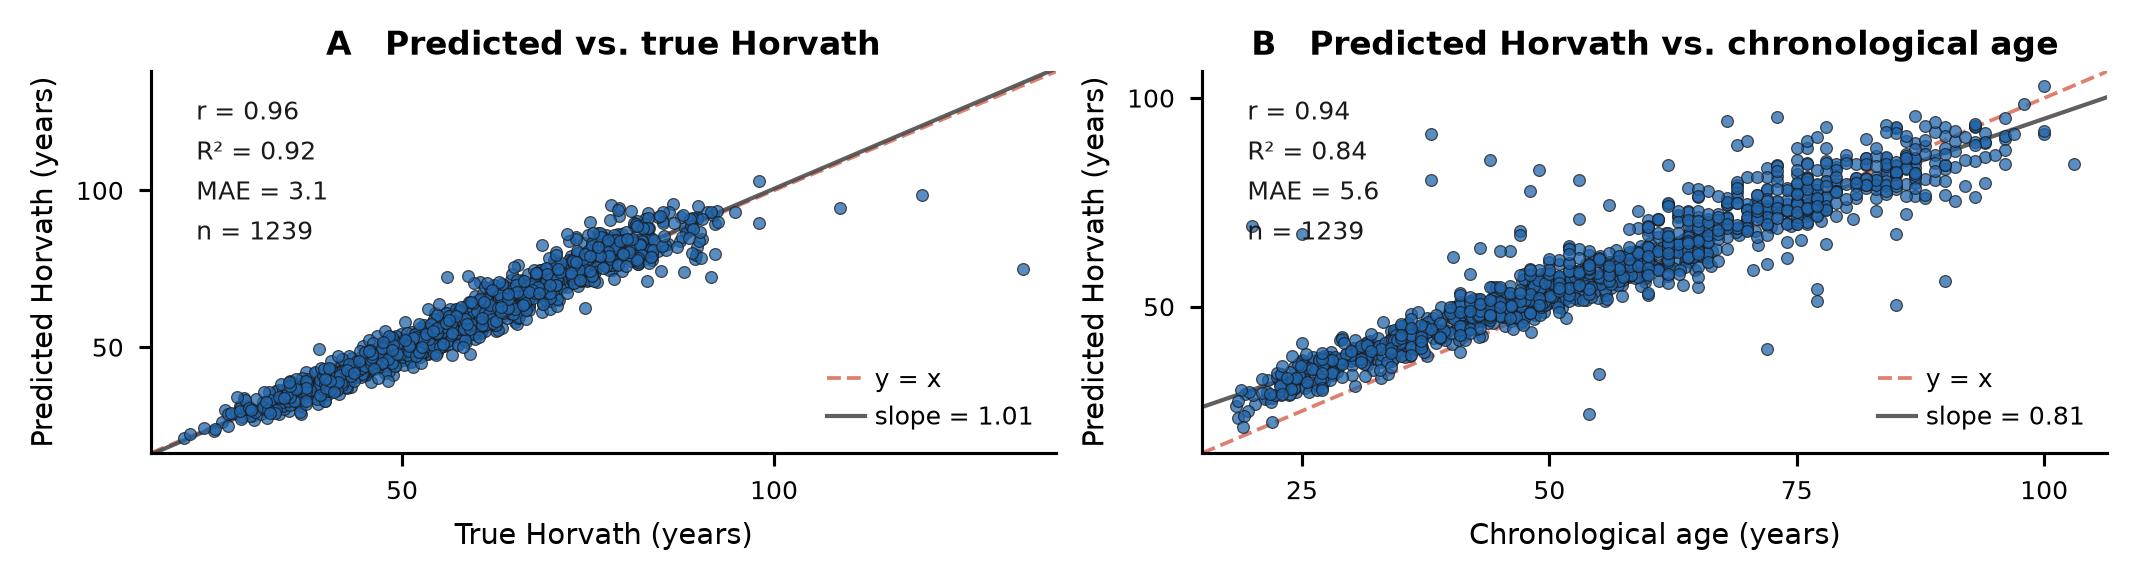

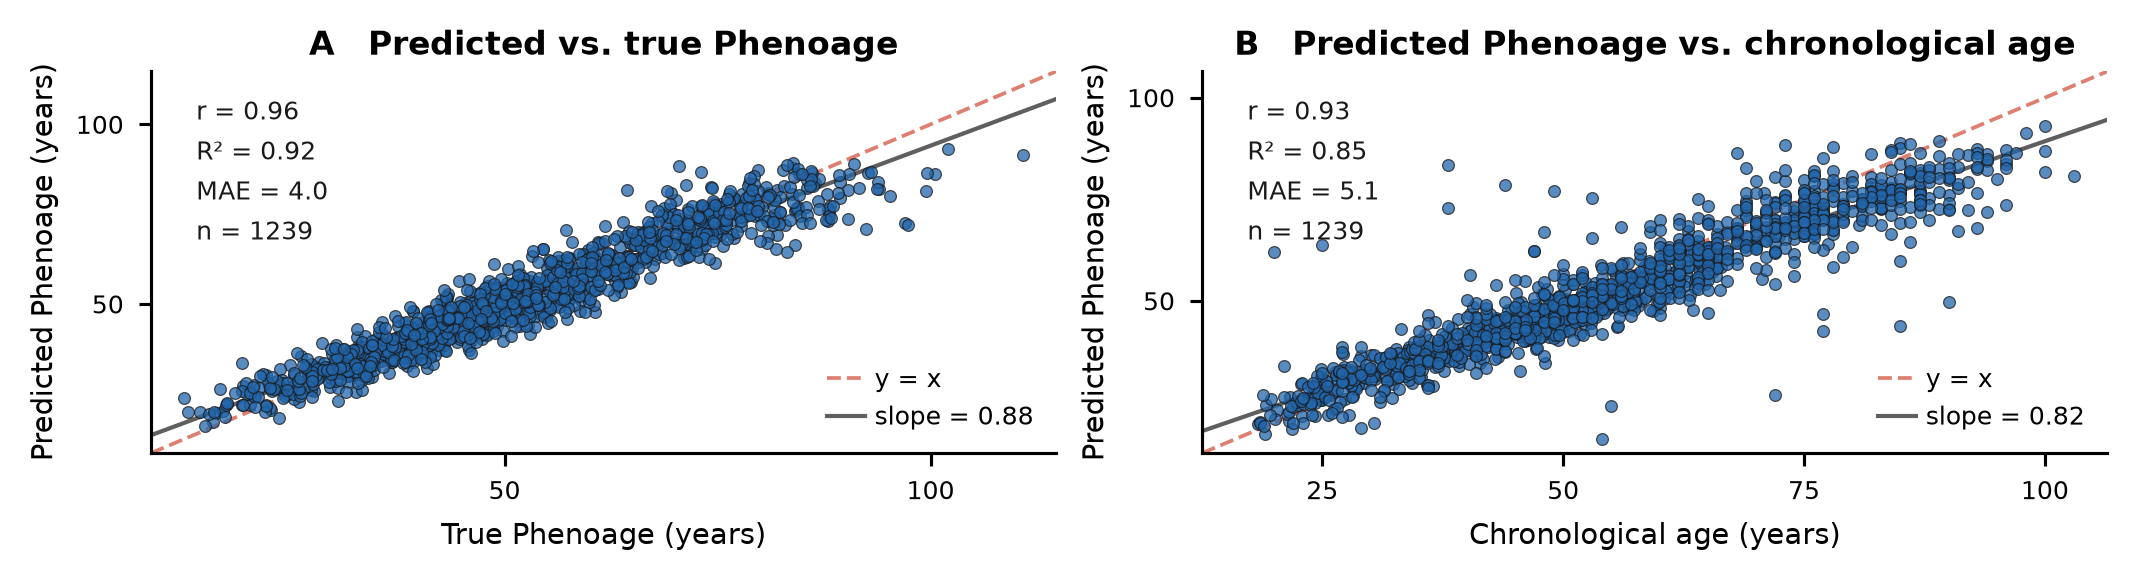

In [13]:
# One clock at a time
fig, (ax_a, ax_b), stats = eu.plot_clock_panels(
    predictions, "horvath_age",
    chron_clock  = "age",          # column to use as chronological age
    save_path    = None,   # saves .pdf + .png, or None
    fig_width_mm = 89,             # NM single-column width
)

# All clocks at once (skips chron_clock itself)
results = eu.plot_all_clock_panels(predictions, clock_names,
                                   chron_clock="age", save_dir=None)